# 3. Implications for Astrophysical Formation Channels

In [2]:
import numpy as np
import scipy as sp
import pandas as pd

import sys
sys.path.append("../emri_tools")
from utils import load_hdf5

import matplotlib.pyplot as plt
from seaborn import color_palette
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": "Computer Modern",
    "text.latex.preamble": r"\usepackage{amsfonts}",
    "font.size": 17,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "legend.frameon": False
})

### 1.1. EMRI Populations from Different Formation Channels

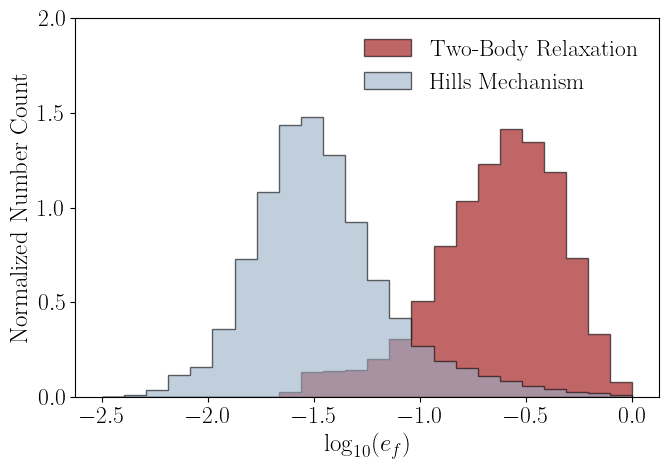

In [3]:
filename = "../populations/relaxation_channel.csv"
df = pd.read_csv(filename)

df = df.sort_values(by="epl", ascending=True).reset_index(drop=True)
        
ef_rel = df["epl"].values
weight_rel = df["weight"].values

filename = "../populations/hills_mechanism.csv"
df = pd.read_csv(filename)

df = df.sort_values(by="epl", ascending=True).reset_index(drop=True)
        
ef_hills = df["epl"].values

bins = np.linspace(-2.5, 0, 25)

plt.figure(figsize=(7,5))

plt.hist(np.log10(ef_rel), weights=weight_rel, bins=bins, density=True, histtype="stepfilled", 
         alpha=0.6, edgecolor="black", linewidth=1, color="#990000", label="Two-Body Relaxation")
plt.hist(np.log10(ef_hills), bins=bins, density=True, histtype="stepfilled", 
         alpha=0.6, color="#98AFC7", edgecolor="black", linewidth=1, label="Hills Mechanism")

plt.xticks(np.arange(-2.5, 0.1, 0.5))
plt.yticks(np.arange(0, 2.1, 0.5))
plt.ylim([0, 2])
plt.xlabel(r"$\log_{10}(e_f)$")
plt.ylabel("Normalized Number Count")
plt.legend(loc="upper right")
plt.tight_layout()
#plt.savefig('../figures/3_populations_dist.pdf', bbox_inches='tight')
plt.show()

### 1.2. FAP Threshold for the Detection Statistic

2.5064733634353376


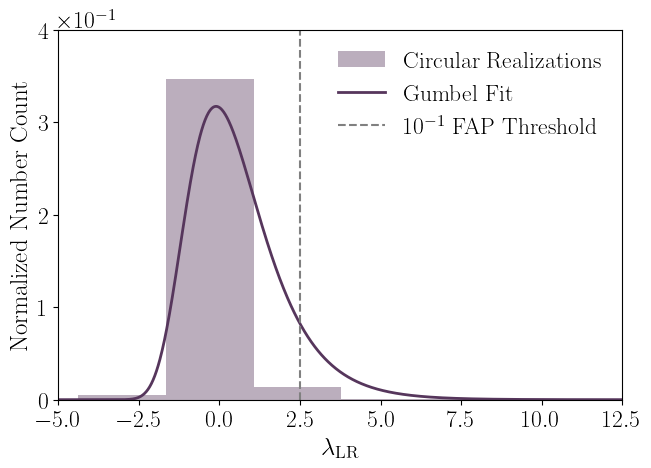

In [4]:
fap = 0.1

filepath = f"../results/3_pop_1_mode_ef_0_noise.h5"
df = load_hdf5(filepath)

vals_lambda = df["lambda_LR"].values

mu, beta = sp.stats.gumbel_r.fit(vals_lambda)
lambda_thr = sp.stats.gumbel_r.isf(fap, loc=mu, scale=beta)
print(lambda_thr)

plt.figure(figsize=(7,5))

counts, bins, _ = plt.hist(vals_lambda, bins=7, density=True, alpha=0.4, color="#56365C", label="Circular Realizations")

x = np.linspace(-5, 12.5, 1000)

plt.plot(x, sp.stats.gumbel_r.pdf(x, mu, beta), lw=2, color="#56365C", label="Gumbel Fit")

plt.axvline(lambda_thr, color="grey", ls="--", label=fr"$10^{{-1}}$ FAP Threshold")

plt.xlim([-5, 12.5])
plt.xticks(np.arange(-5, 12.6, 2.5))
plt.ylim([0, 4e-1])

plt.xlabel(r"$\lambda_{\rm LR}$")
plt.ylabel("Normalized Number Count")
plt.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.legend()
plt.tight_layout()
#plt.savefig('../figures/3_circular_realizations.pdf', bbox_inches='tight')
plt.show()

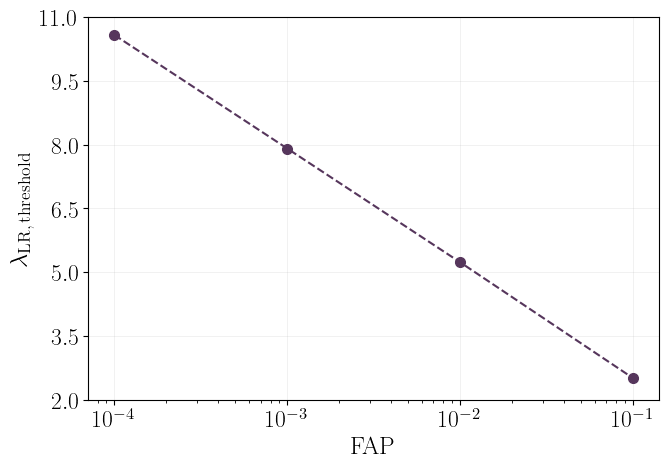

In [5]:
filepath = f"../results/3_pop_1_mode_ef_0_noise.h5"
df = load_hdf5(filepath)

vals_lambda = df["lambda_LR"].values

mu, beta = sp.stats.gumbel_r.fit(vals_lambda)
vals_fap = 10 ** np.arange(-4, -0.9, 1)
vals_lambda_thr_fap = []
    
for val_fap in vals_fap:
    
    lambda_thr_fap = sp.stats.gumbel_r.isf(val_fap, loc=mu, scale=beta)
    vals_lambda_thr_fap += [lambda_thr_fap]

plt.figure(figsize=(7,5))
    
plt.plot(vals_fap, vals_lambda_thr_fap, "o--", markersize=7, color="#56365C")

plt.ylim([2, 11])
plt.yticks(np.arange(2, 11.1, 1.5))
        
plt.xlabel("FAP")
plt.ylabel(r"$\lambda_{\rm LR, \,threshold}$")
plt.xscale("log")
plt.grid(True, alpha=0.25, linewidth=0.5)

plt.tight_layout()
#plt.savefig('../figures/3_fap_threshold.pdf', bbox_inches='tight')
plt.show()

### 1.3. Probability of Detecting Eccentricity

In [18]:
vals_ef = [10**(-2.5), 10**(-2.25), 10**(-2), 10**(-1.75), 10**(-1.5), 10**(-1.25), 10**(-1), 10**(-0.75), 10**(-0.5), 10**(-0.25), 0.82]
labels = ["1e-2.5", "1e-2.25", "1e-2", "1e-1.75", "1e-1.5", "1e-1.25", "1e-1", "1e-0.75", "1e-0.5", "1e-0.25", "0.82"]

fractions_det = []
    
for ef, label in zip(vals_ef, labels):
    
    filepath = f"../results/3_pop_1_mode_ef_{label}_noise.h5"
    df = load_hdf5(filepath)
    vals_lambda = df["lambda_LR"].values
    
    f_det = np.mean(vals_lambda > lambda_thr)
    fractions_det += [f_det]
    
P_det_interp = sp.interpolate.interp1d(
    np.log10(vals_ef),
    fractions_det,
    kind="linear",
    bounds_error=False,
    fill_value=(fractions_det[0], fractions_det[-1])
    )

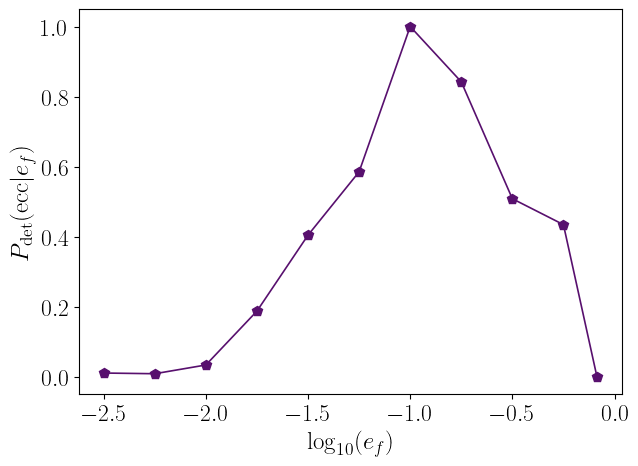

In [32]:
plt.figure(figsize=(7,5))

plt.plot(np.log10(vals_ef), P_det_interp(np.log10(vals_ef)), 'p-', lw=1.2, markersize=7, c="#58106e")
plt.xticks(np.arange(-2.5, 0.1, 0.5))
plt.xlabel(r"$\log_{10}(e_f)$")
plt.ylabel(r"$P_{\rm det}(\textrm{ecc} | e_f)$")
#plt.savefig('../figures/3_det_probability.pdf', bbox_inches='tight')
plt.show()

### 1.4. Fraction of Systems with Detectable Eccentricity

In [33]:
print("Expected fraction of systems with detectable eccentricity")

# Two-body relaxation channel

filename = "../populations/relaxation_channel.csv"
df = pd.read_csv(filename)

df = df.sort_values(by="epl", ascending=True).reset_index(drop=True)
        
ef_pop = df["epl"].values
weight_pop = df["weight"].values

valid = ef_pop <= 0.82
ef_pop_rel = ef_pop[valid]
weight_pop_rel = weight_pop[valid] / np.sum(weight_pop[valid])

P_det_pop = P_det_interp(np.log10(ef_pop_rel))
fraction_detected = np.sum(weight_pop_rel * P_det_pop)
print(f"Two-body relaxation channel: {fraction_detected*100: .2f}%.")

# Hills Mechanism

filename = "../populations/hills_mechanism.csv"
df = pd.read_csv(filename)

df = df.sort_values(by="epl", ascending=True).reset_index(drop=True)

ef_pop = df["epl"].values

valid = ef_pop <= 0.82
ef_pop_hills = ef_pop[valid]

P_det_pop = P_det_interp(np.log10(ef_pop_hills))
fraction_detected = np.mean(P_det_pop)
print(f"Hills mechanism: {fraction_detected*100: .2f}%.")

Expected fraction of systems with detectable eccentricity
Two-body relaxation channel:  63.75%.
Hills mechanism:  42.05%.


### 1.5. Scatter plots

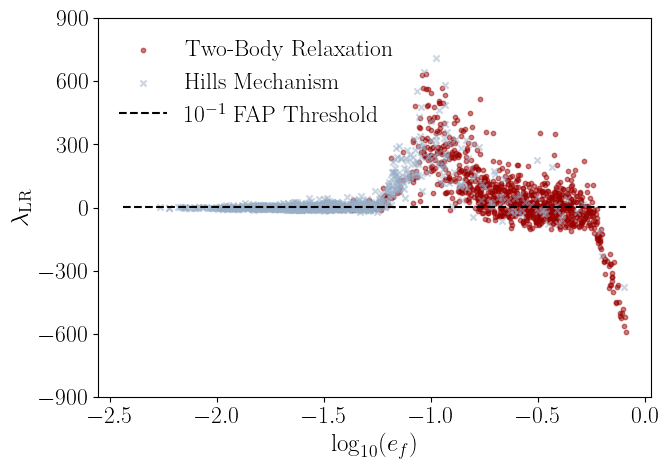

In [35]:
rng = np.random.default_rng(42)

vals_mu = []
vals_beta = []

for label, ef in zip(labels, vals_ef):

    filepath = f"../results/3_pop_1_mode_ef_{label}_noise.h5"
    df = load_hdf5(filepath)

    vals_lambda = df["lambda_LR"].values

    mu, beta = sp.stats.gumbel_r.fit(vals_lambda)
    vals_mu += [mu]
    vals_beta += [beta]

mu_interp = sp.interpolate.interp1d(
        np.log10(vals_ef),
        vals_mu,
        kind="linear",
        bounds_error=False,
        fill_value=(vals_mu[0], vals_mu[-1])
    )

beta_interp = sp.interpolate.interp1d(
        np.log10(vals_ef),
        vals_beta,
        kind="linear",
        bounds_error=False,
        fill_value=(vals_beta[0], vals_beta[-1])
    )

N_total = 1000

# Two-Body Relaxation

ef_samples_rel = rng.choice(ef_pop_rel, size=N_total, p=weight_pop_rel)

mu_vals = mu_interp(np.log10(ef_samples_rel))
beta_vals = beta_interp(np.log10(ef_samples_rel))

gumbel_noise = rng.gumbel(size=N_total)

lambda_samples_rel = mu_vals + beta_vals * gumbel_noise

# Hills Mechanism

ef_samples_hills = rng.choice(ef_pop_hills, size=N_total)

mu_vals = mu_interp(np.log10(ef_samples_hills))
beta_vals = beta_interp(np.log10(ef_samples_hills))

gumbel_noise = rng.gumbel(size=N_total)

lambda_samples_hills = mu_vals + beta_vals * gumbel_noise

plt.figure(figsize=(7,5))

plt.scatter(np.log10(ef_samples_rel), lambda_samples_rel,
            label="Two-Body Relaxation",
            color="#990000", marker=".", s=40, alpha=0.5)

plt.scatter(np.log10(ef_samples_hills), lambda_samples_hills,
            label="Hills Mechanism",
            color="#98AFC7", marker="x", s=20, alpha=0.5)

plt.hlines(lambda_thr,
           np.log10(ef_pop_hills[0]),
           np.log10(ef_pop_rel[-1]),
           color="black", ls="--",
           label=r"$10^{-1}$ FAP Threshold")

plt.xticks(np.arange(-2.5, 0.1, 0.5))
plt.ylim([-900, 900])
plt.yticks(np.arange(-900, 901, 300))

plt.xlabel(r"$\log_{10}(e_f)$")
plt.ylabel(r"$\lambda_{\rm LR}$")

plt.legend()
plt.tight_layout()
#plt.savefig('../figures/3_scatter_populations.pdf', bbox_inches='tight')
plt.show()